# Computer vision
1. Understanding
    1. Image - classification
    2. Image - Object classification & localization (single object / subject)
    3. Multiple objects - classification + localization
    4. Segmentation
2. Generation

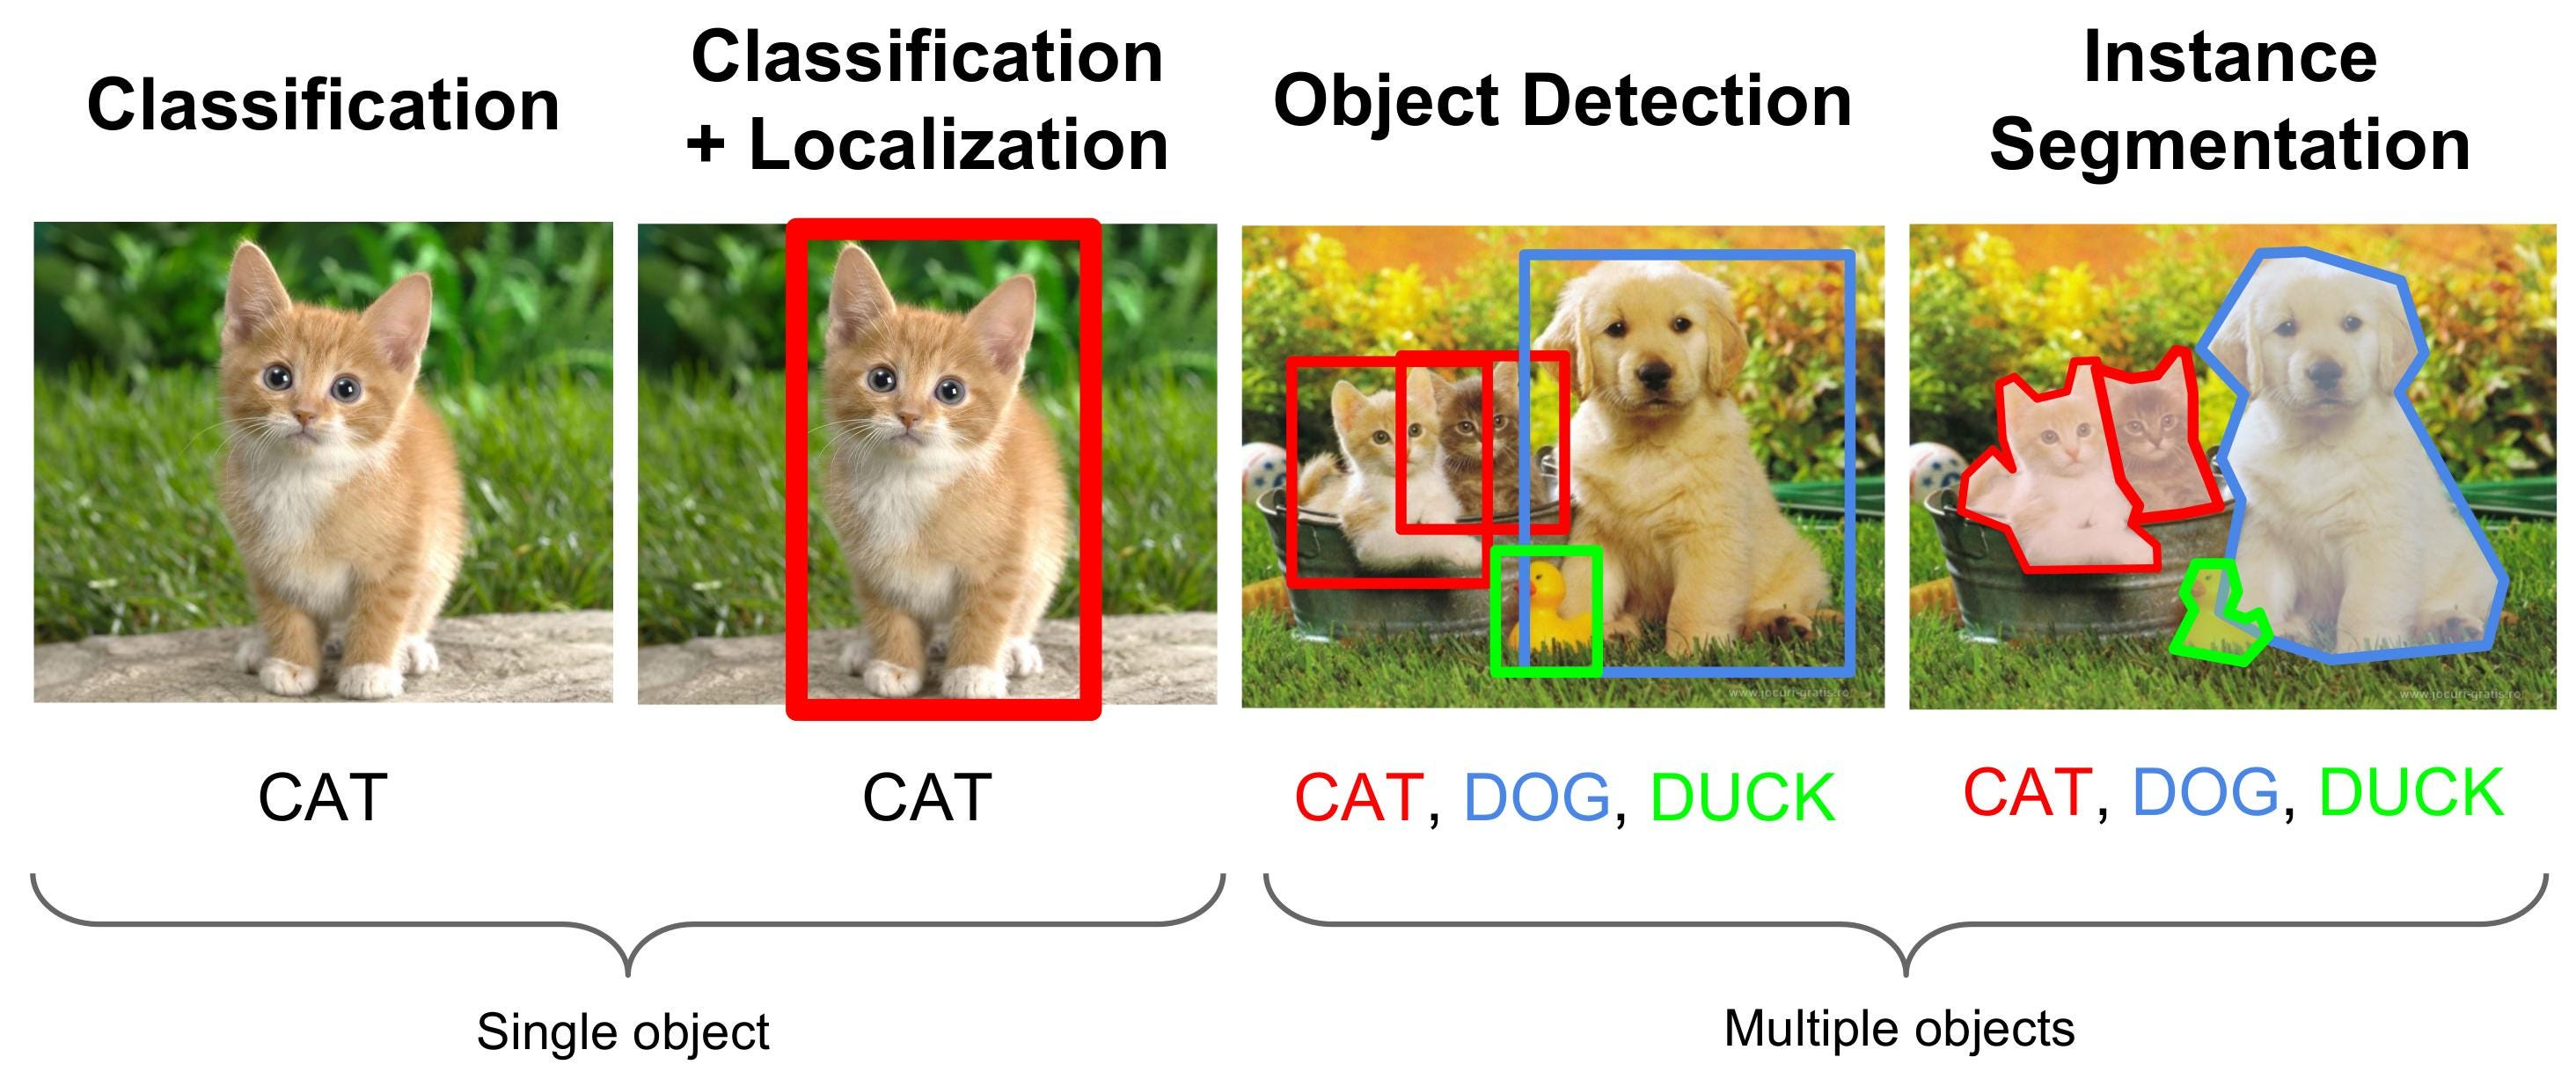

#PLEASE NOTE: We have to keep the model light!

What is a light weight model:
1. lower parameter count
2. lesser size for storage
3. lower env deps

# Smaller models are preferred - Docerization is an useful way as well to ship the whole code

# CIFAR-10 image classification — Kaggle download, train, test, export ONNX

This notebook **downloads CIFAR-10 from Kaggle**, including **50,000 labeled training images and 10,000 labeled test images** across ten categories. We keep the dataset's test images separate, and reserve **5,000 training images for validation**, giving **45,000 train / 5,000 validation / 10,000 test**.

**Kaggle dataset:** [CIFAR-10 PNGs in folders](https://www.kaggle.com/datasets/swaroopkml/cifar10-pngs-in-folders) (a labeled image-folder version of CIFAR-10). This is **not** the Kaggle CIFAR-10 competition archive, whose competition test set has hidden labels and extra junk images.

**Train in Jupyter or Google Colab, not on 1 GiB EC2.** After training, copy `artifacts/model.onnx` and `artifacts/classes.json` beside `app.py` on EC2.

For local Jupyter, install `requirements-train.txt` first. On Colab, select a GPU runtime; the setup cell installs download/export helpers. Public Kaggle datasets normally do not require API credentials, but if Kaggle requests sign-in, authenticate to Kaggle.

## 1. Setup

In [10]:
# In Colab, PyTorch/torchvision are usually preinstalled.
# For local Jupyter, you can instead install requirements-train.txt once.
%pip install -q kagglehub onnx onnxruntime

In [12]:
from pathlib import Path
import copy
import json
import random

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("data")
EXPORT_DIR = Path("artifacts")
DATA_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# CIFAR-10 source images are 32x32. Resize for a lightweight pretrained
# MobileNetV3-Small backbone. The Flask app reads model input dimensions.
IMAGE_SIZE = 128
BATCH_SIZE = 64 if torch.cuda.is_available() else 32
EPOCHS = 5
LEARNING_RATE = 1e-3
VAL_FRACTION = 0.10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", DEVICE)
print("Input image size:", IMAGE_SIZE, "x", IMAGE_SIZE)

Training device: cuda
Input image size: 128 x 128


## 2. Download CIFAR-10 **training and test** images from Kaggle

The following one-liner fetches the [labeled CIFAR-10 PNG dataset](https://www.kaggle.com/datasets/swaroopkml/cifar10-pngs-in-folders) using `kagglehub`. We detect the dataset's `train/<class>/` and `test/<class>/` directories automatically and load them with `ImageFolder`. KaggleHub caches the dataset on disk.

All images are resized to 128 × 128 and normalized in the same way as Flask inference. Only training images receive random flips.

In [13]:
import kagglehub

# One Kaggle link supplies both labeled training and test images.
dataset_path = Path(kagglehub.dataset_download('swaroopkml/cifar10-pngs-in-folders'))
print('Downloaded Kaggle dataset to:', dataset_path)

# Find train/test folders, even when Kaggle puts them in a nested directory.
CIFAR_CLASSES = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck',
]

def find_data_folders(root):
    for train_dir in [root / 'train', *root.rglob('train')]:
        test_dir = train_dir.parent / 'test'
        if not train_dir.is_dir() or not test_dir.is_dir():
            continue
        train_classes = sorted(p.name for p in train_dir.iterdir() if p.is_dir())
        test_classes = sorted(p.name for p in test_dir.iterdir() if p.is_dir())
        if train_classes == CIFAR_CLASSES and test_classes == CIFAR_CLASSES:
            return train_dir, test_dir
    raise FileNotFoundError(
        f'Could not find train/<class>/ and test/<class>/ folders in {root}. '
        'Check the downloaded Kaggle dataset layout.'
    )

train_dir, test_dir = find_data_folders(dataset_path)
print('Training folder:', train_dir)
print('Testing folder: ', test_dir)

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_source = datasets.ImageFolder(str(train_dir), transform=train_tf)
val_source = datasets.ImageFolder(str(train_dir), transform=eval_tf)
test_ds = datasets.ImageFolder(str(test_dir), transform=eval_tf)

class_names = list(train_source.classes)
assert class_names == CIFAR_CLASSES == test_ds.classes
assert len(train_source) == 50_000 and len(test_ds) == 10_000, (
    f'Unexpected CIFAR-10 dataset size: {len(train_source)} train, {len(test_ds)} test'
)
print('CIFAR-10 classes:', class_names)
print('Training pool:', len(train_source))
print('Held-out test images:', len(test_ds))

Using Colab cache for faster access to the 'cifar10-pngs-in-folders' dataset.
Downloaded Kaggle dataset to: /kaggle/input/cifar10-pngs-in-folders
Training folder: /kaggle/input/cifar10-pngs-in-folders/cifar10/cifar10/train
Testing folder:  /kaggle/input/cifar10-pngs-in-folders/cifar10/cifar10/test
CIFAR-10 classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training pool: 50000
Held-out test images: 10000


## 3. Make a reproducible stratified validation split

Take 500 images per class from Kaggle's 50,000 labeled training images for validation, leaving 4,500 per class for training. The **separate Kaggle test folder** is only used for the final evaluation.

In [4]:
train_indices, val_indices = [], []
for class_id in range(len(class_names)):
    indices = [i for i, target in enumerate(train_source.targets)
               if target == class_id]
    random.Random(SEED + class_id).shuffle(indices)
    n_val = int(len(indices) * VAL_FRACTION)
    val_indices.extend(indices[:n_val])
    train_indices.extend(indices[n_val:])

train_ds = Subset(train_source, train_indices)
val_ds = Subset(val_source, val_indices)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=0, pin_memory=(DEVICE.type == "cuda"))
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=0, pin_memory=(DEVICE.type == "cuda"))
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                     num_workers=0, pin_memory=(DEVICE.type == "cuda"))

assert len(train_ds) == 45_000 and len(val_ds) == 5_000
print(f"Train: {len(train_ds):,} | Validation: {len(val_ds):,} | "
      f"Test: {len(test_ds):,}")
print("Test sample shape:", tuple(test_ds[0][0].shape))

Train: 45,000 | Validation: 5,000 | Test: 10,000
Test sample shape: (3, 128, 128)


## 4. Train MobileNetV3-Small

Use ImageNet-pretrained MobileNetV3-Small as a compact feature extractor and fit its final classifier to **10 CIFAR-10 classes**. Freezing the backbone makes training simpler and reduces GPU memory requirements. For higher accuracy, you can unfreeze part of the backbone and fine-tune longer (at greater training cost).

The pretrained weights are downloaded once on the training machine. They are **not** needed as a separate download on EC2 after ONNX export.

In [5]:
weights = models.MobileNet_V3_Small_Weights.DEFAULT
model = models.mobilenet_v3_small(weights=weights)
for p in model.parameters():
    p.requires_grad = False #where the finetuning is blocked - No retraining of weights

n_features = model.classifier[-1].in_features #Drop the imagenet classifier head
model.classifier[-1] = nn.Linear(n_features, len(class_names))
model = model.to(DEVICE)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.classifier[-1].parameters(), lr=LEARNING_RATE)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 127MB/s]


Trainable parameters: 10250


In [6]:
best_val_acc = -1.0
best_weights = None

for epoch in range(EPOCHS):
    model.train()
    model.features.eval()  # keep frozen BatchNorm statistics unchanged
    train_correct, train_count, train_loss = 0, 0, 0.0

    for images, targets in train_dl:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        train_correct += (logits.argmax(dim=1) == targets).sum().item()
        train_count += images.size(0)

    model.eval()
    val_correct, val_count = 0, 0
    with torch.inference_mode():
        for images, targets in val_dl:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            logits = model(images)
            val_correct += (logits.argmax(dim=1) == targets).sum().item()
            val_count += images.size(0)

    val_acc = val_correct / val_count
    print(f"Epoch {epoch + 1}/{EPOCHS} | "
          f"train loss {train_loss / train_count:.4f} | "
          f"train acc {train_correct / train_count:.1%} | "
          f"val acc {val_acc:.1%}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model.state_dict())

model.load_state_dict(best_weights)
model.eval()
print(f"Best validation accuracy: {best_val_acc:.1%}")

Epoch 1/5 | train loss 0.6511 | train acc 78.4% | val acc 82.2%
Epoch 2/5 | train loss 0.5071 | train acc 82.4% | val acc 82.9%
Epoch 3/5 | train loss 0.4832 | train acc 83.3% | val acc 83.5%
Epoch 4/5 | train loss 0.4754 | train acc 83.5% | val acc 83.7%
Epoch 5/5 | train loss 0.4665 | train acc 83.7% | val acc 83.2%
Best validation accuracy: 83.7%


## 5. Evaluate on **Kaggle's held-out labeled CIFAR-10 test folder**

The test images and labels are separate from training and validation. Note that this is the Kaggle **dataset** mirror, not the unlabeled Kaggle **competition** test data.

In [7]:
model.eval()
correct, total = 0, 0
class_correct = [0] * len(class_names)
class_total = [0] * len(class_names)

with torch.inference_mode():
    for images, targets in test_dl:
        logits = model(images.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu()
        correct += (predictions == targets).sum().item()
        total += targets.size(0)
        for cls in range(len(class_names)):
            mask = targets == cls
            class_total[cls] += mask.sum().item()
            class_correct[cls] += ((predictions == targets) & mask).sum().item()

print(f"Held-out test accuracy: {correct / total:.1%} ({correct}/{total})")
for cls, name in enumerate(class_names):
    print(f"  {name}: {class_correct[cls] / class_total[cls]:.1%} "
          f"({class_correct[cls]}/{class_total[cls]})")

Held-out test accuracy: 83.4% (8343/10000)
  airplane: 86.9% (869/1000)
  automobile: 89.1% (891/1000)
  bird: 75.2% (752/1000)
  cat: 68.3% (683/1000)
  deer: 79.3% (793/1000)
  dog: 79.0% (790/1000)
  frog: 91.2% (912/1000)
  horse: 86.3% (863/1000)
  ship: 89.5% (895/1000)
  truck: 89.5% (895/1000)


## 6. Export the classifier to ONNX for EC2

The Flask app only needs `artifacts/model.onnx` and `artifacts/classes.json`. It will detect the ONNX model's input size automatically (128 × 128 by default).

In [8]:
model = model.cpu().eval()
example = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)
onnx_path = EXPORT_DIR / "model.onnx"

torch.onnx.export(
    model,
    example,
    str(onnx_path),
    input_names=["images"],
    output_names=["logits"],
    opset_version=17,
    dynamo=False,
)
with (EXPORT_DIR / "classes.json").open("w", encoding="utf-8") as f:
    json.dump(class_names, f, indent=2)

print("Wrote:", onnx_path, f"({onnx_path.stat().st_size / 1024**2:.1f} MB)")
print("Wrote:", EXPORT_DIR / "classes.json")

/tmp/ipykernel_1178/992806036.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Wrote: artifacts/model.onnx (5.8 MB)
Wrote: artifacts/classes.json


## 7. Verify ONNX matches PyTorch before deployment

In [9]:
import onnx
import onnxruntime as ort

onnx.checker.check_model(onnx.load(str(onnx_path)))
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
with torch.inference_mode():
    torch_logits = model(example).numpy()
onnx_logits = session.run(None, {session.get_inputs()[0].name: example.numpy()})[0]
np.testing.assert_allclose(onnx_logits, torch_logits, rtol=1e-3, atol=1e-3)
print("ONNX export verified. Upload artifacts/ with app.py to EC2.")

ONNX export verified. Upload artifacts/ with app.py to EC2.
